# Chapitre 12 - Exercices 12.11 à 12.15

Ces exercices accompagnent la section *Doing the Right Thing* (cours 6 et 7). Le livre
n'a ni calculs ni code sur ces sujets ; les exercices donnent des ordres de grandeur et
des mécanismes vérifiables, sans prétendre réduire l'éthique à des formules :

- **12.11** : calibration contre égalité des taux d'erreur, un théorème
  d'impossibilité (calcul et simulation) ;
- **12.12** : combien de personnes sont ré-identifiables, et à quel prix
  les protéger (calcul et mini-lab) ;
- **12.13** : réponse randomisée, taille d'échantillon et déni plausible
  (calcul et simulation) ;
- **12.14** : boucle de rétroaction des patrouilles et correction de
  l'échantillonnage (mini-lab) ;
- **12.15** : durée de conservation, agrégation et risque de fuite
  (calcul et simulation).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import ethics as et
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 12.11 : calibration contre égalité des taux d'erreur

**Énoncé.** Un score prédit la probabilité de défaut de paiement. On refuse le crédit
quand le score dépasse un seuil. Pour un groupe de personnes, on note $\pi$ le taux de
base (proportion réelle de défauts), $\mathrm{FPR}$ la part des bons payeurs refusés,
$\mathrm{FNR}$ la part des mauvais payeurs acceptés, $\mathrm{PPV}$ la part de vrais
défauts parmi les refusés.

1. Montrer l'identité $\mathrm{FPR} = \dfrac{\pi}{1-\pi}\cdot\dfrac{1-\mathrm{PPV}}{\mathrm{PPV}}\cdot(1-\mathrm{FNR})$.
2. Deux groupes ont des taux de base différents, $\pi_A = 0{,}2$ et $\pi_B = 0{,}4$. On
   exige la même précision des refus ($\mathrm{PPV} = 0{,}6$) et le même taux de mauvais
   payeurs acceptés ($\mathrm{FNR} = 0{,}3$) dans les deux groupes. Calculer le
   $\mathrm{FPR}$ de chaque groupe. Conclure.
3. Vérifier par simulation : générer un score **parfaitement calibré** dans chaque
   groupe, appliquer un seuil commun de 0,5, et mesurer FPR, FNR et PPV par groupe.
4. Que faut-il en retenir pour l'ingénieur qui « choisit une métrique d'équité » ?

**Rappels.** Cours 6, section 2 (sous-section *Bias and discrimination*) : un modèle peut sembler juste selon un
critère et injuste selon un autre ; la calibration (à score égal, même taux observé)
est l'un des critères possibles.

**Solution.**

*1.* Sur $n$ personnes : $n\pi$ mauvais payeurs, dont $\mathrm{TP} = n\pi(1-\mathrm{FNR})$
refusés ; $n(1-\pi)$ bons payeurs, dont $\mathrm{FP} = n(1-\pi)\mathrm{FPR}$ refusés. Par
définition $\mathrm{PPV} = \mathrm{TP}/(\mathrm{TP}+\mathrm{FP})$, donc
$\mathrm{FP} = \mathrm{TP}\,(1-\mathrm{PPV})/\mathrm{PPV}$. En remplaçant :
$n(1-\pi)\mathrm{FPR} = n\pi(1-\mathrm{FNR})(1-\mathrm{PPV})/\mathrm{PPV}$, d'où l'identité.

*2.* $\mathrm{FPR}_A = \tfrac{0{,}2}{0{,}8}\cdot\tfrac{0{,}4}{0{,}6}\cdot 0{,}7 \approx 0{,}117$ et
$\mathrm{FPR}_B = \tfrac{0{,}4}{0{,}6}\cdot\tfrac{0{,}4}{0{,}6}\cdot 0{,}7 \approx 0{,}311$. À
précision et taux de faux négatifs égaux, les bons payeurs du groupe B sont refusés
**près de 2,7 fois plus souvent**. Dès que les taux de base diffèrent (et que le
classifieur n'est pas parfait), on ne peut pas égaliser à la fois PPV, FNR et FPR :
c'est le théorème d'impossibilité de Chouldechova (2017), proche de celui de Kleinberg,
Mullainathan et Raghavan sur la calibration.

*3.* Voir la vérification. *4.* Le choix d'une métrique d'équité n'est pas technique :
chaque critère protège un intérêt différent (la banque veut un PPV égal, le bon payeur
veut un FPR égal). Il faut l'expliciter, le justifier, et se demander d'abord **pourquoi**
les taux de base diffèrent : si c'est l'effet de discriminations passées dans les
étiquettes (cours 6), aucune métrique calculée sur ces étiquettes ne le
révélera.

**Vérification** : calcul direct de la question 2, puis simulation. Dans chaque groupe,
le score $s$ suit une loi bêta de moyenne $\pi_g$, et le défaut survient avec
probabilité exactement $s$ : le score est calibré par construction.

FPR_A = 0.117 ; FPR_B = 0.311


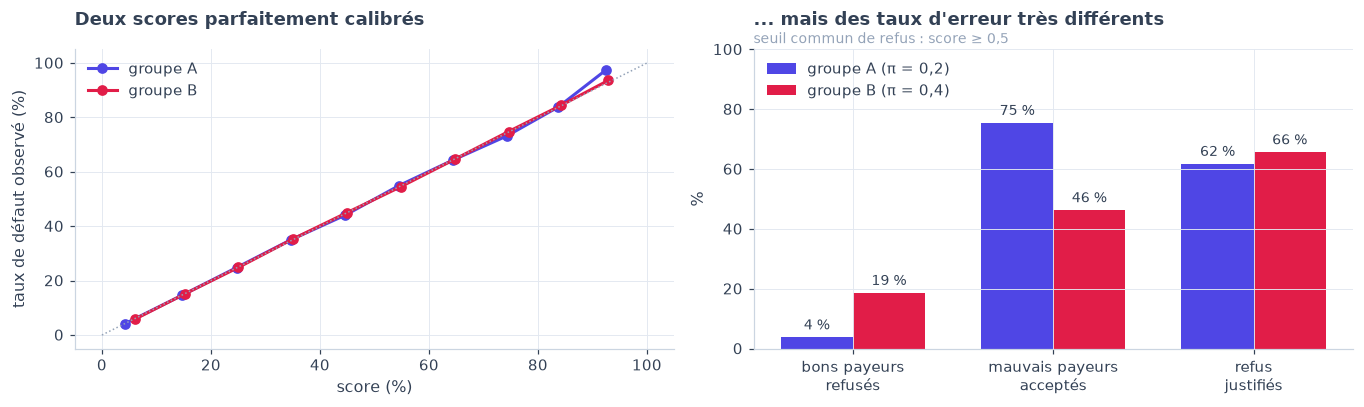

,taux de base,FPR (bons refusés),FNR (mauvais acceptés),PPV (refus justifiés)
groupe,,,,
A,0.200,0.038,0.755,0.618
B,0.399,0.186,0.463,0.657


In [2]:
def fpr_identity(pi, ppv, fnr):
    return pi / (1 - pi) * (1 - ppv) / ppv * (1 - fnr)

print(f"FPR_A = {fpr_identity(0.2, 0.6, 0.3):.3f} ; FPR_B = {fpr_identity(0.4, 0.6, 0.3):.3f}")

n = 200_000
rows, cal = [], []
for gname, pi in [("A", 0.2), ("B", 0.4)]:
    conc = 4.0
    s = rng.beta(pi * conc, (1 - pi) * conc, size=n)
    y = rng.random(n) < s                       # défaut
    refuse = s >= 0.5
    rows.append({"groupe": gname, "taux de base": y.mean(), "FPR (bons refusés)": refuse[~y].mean(),
                 "FNR (mauvais acceptés)": (~refuse[y]).mean(), "PPV (refus justifiés)": y[refuse].mean()})
    bins = np.linspace(0, 1, 11)
    idx = np.digitize(s, bins[1:-1])
    cal.append((gname, [s[idx == b].mean() for b in range(10)], [y[idx == b].mean() for b in range(10)]))
R = pd.DataFrame(rows).set_index("groupe")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax = axes[0]
for (gname, sx, yx), c in zip(cal, [INDIGO, ROSE]):
    ax.plot(np.array(sx) * 100, np.array(yx) * 100, "o-", color=c, label=f"groupe {gname}")
ax.plot([0, 100], [0, 100], ":", color=GRAY, lw=1)
ax.set_xlabel("score (%)"); ax.set_ylabel("taux de défaut observé (%)")
ax.set_title("Deux scores parfaitement calibrés")
ax.legend()
ax = axes[1]
x = np.arange(3)
cols = ["FPR (bons refusés)", "FNR (mauvais acceptés)", "PPV (refus justifiés)"]
ax.bar(x - 0.18, R.loc["A", cols] * 100, 0.36, color=INDIGO, label="groupe A (π = 0,2)")
ax.bar(x + 0.18, R.loc["B", cols] * 100, 0.36, color=ROSE, label="groupe B (π = 0,4)")
annotate_bars(ax, "{:.0f} %")
ax.set_xticks(x, ["bons payeurs\nrefusés", "mauvais payeurs\nacceptés", "refus\njustifiés"])
ax.set_ylim(0, 100); ax.set_ylabel("%")
ax.set_title("... mais des taux d'erreur très différents")
subtitle(ax, "seuil commun de refus : score ≥ 0,5")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
R

Les deux scores sont calibrés (les courbes suivent la diagonale), mais avec le même
seuil le groupe B, au taux de base plus élevé, voit ses bons payeurs refusés bien plus
souvent, et ses mauvais payeurs moins souvent acceptés. Changer de seuil par groupe
égaliserait certains taux et en déséquilibrerait d'autres : l'identité de la question
1 l'impose.

> **À retenir.** Quand les taux de base diffèrent, calibration, égalité des taux de
> faux positifs et égalité des taux de faux négatifs sont incompatibles. Choisir un
> critère d'équité est un choix de valeurs, à expliciter et à assumer, pas un détail
> d'implémentation.

## Exercice 12.12 : combien de personnes sont ré-identifiables ?

**Énoncé.** On publie un jeu de données « anonymisé » contenant le code postal, la date
de naissance complète et le sexe. On suppose les dates de naissance uniformes sur 80
ans.

1. Dans un code postal de $N$ habitants, estimer la proportion de personnes uniques sur
   (date de naissance, sexe) pour $N$ = 2 000 et $N$ = 20 000.
2. À partir de combien d'habitants moins de la moitié des gens sont-ils uniques ?
3. Même question si l'on ne publie que l'**année** de naissance.
4. Mini-lab : sur la population synthétique du cours (100 000 personnes, 400 codes
   postaux), trouver la généralisation la **moins destructrice** qui rend le jeu
   5-anonyme sur (code postal, naissance, sexe). On autorise le code postal à 5, 4 ou 3
   chiffres et la naissance au jour, au mois, à l'année ou à la décennie.

**Rappels.** Cours 7, section 2 (sous-section *Surveillance*) : $N$ personnes réparties uniformément sur $D$
combinaisons ; une personne est seule avec probabilité $(1-1/D)^{N-1} \approx e^{-N/D}$.
Un jeu est k-anonyme si chaque combinaison de quasi-identifiants est partagée par au
moins $k$ personnes.

**Solution.**

*1.* $D = 365 \times 80 \times 2 = 58\,400$. Pour $N$ = 2 000 : $e^{-2000/58400} \approx
0{,}966$, soit **97 %** d'uniques. Pour $N$ = 20 000 : $e^{-0{,}342} \approx 0{,}71$, encore
**71 %**. Même une ville moyenne ne protège pas.

*2.* $e^{-N/D} < 1/2 \iff N > D \ln 2 \approx 40\,500$ habitants pour un seul code postal.

*3.* Avec l'année seule, $D = 160$ : pour $N$ = 2 000, $e^{-12{,}5} \approx 4 \cdot 10^{-6}$,
personne n'est seul en moyenne, et la moitié est atteinte dès $N \approx 111$. La
précision de la date est le facteur dominant : passer du jour à l'année divise $D$ par
365.

*4.* Voir le mini-lab : on mesure, pour chaque généralisation, le $k$ obtenu et le
nombre de classes distinctes (une mesure grossière de l'information conservée).

**Vérification** : formule contre population simulée, puis recherche exhaustive des
généralisations.

N =   2000 : uniques attendus 96.6%
N =  20000 : uniques attendus 71.0%
seuil de 50 % : N ≈ 40 480 (date) ; 111 (année)
simulation N = 20 000 : 71.0% d'uniques


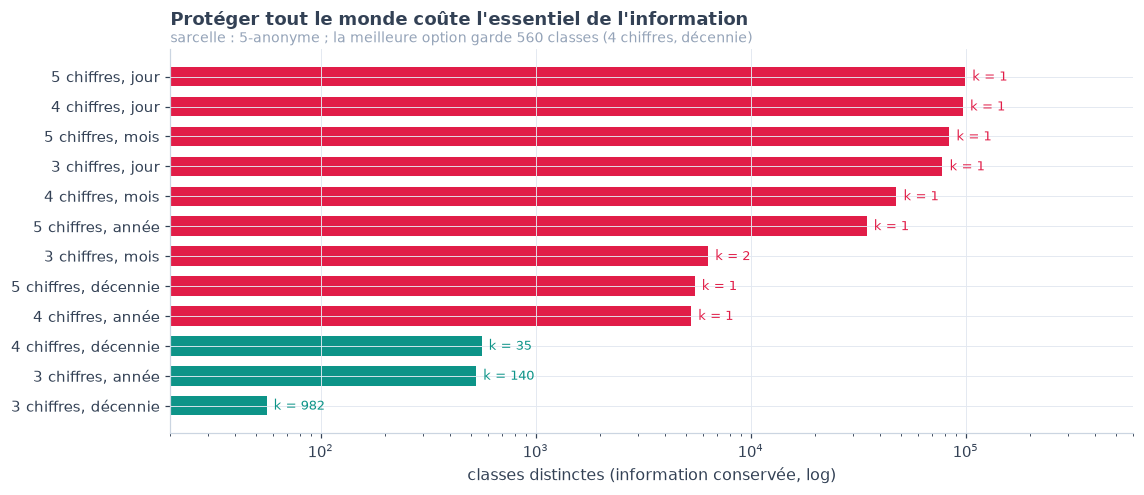

,code postal,naissance,k,classes distinctes,personnes en classe < 5 (%)
7,4 chiffres,décennie,35,560,0.0
10,3 chiffres,année,140,528,0.0
11,3 chiffres,décennie,982,56,0.0


In [3]:
D = 365 * 80 * 2
for N in (2000, 20000):
    print(f"N = {N:>6} : uniques attendus {et.expected_unique_fraction(N, D):.1%}")
print(f"seuil de 50 % : N ≈ {D * np.log(2):,.0f} (date) ; {160 * np.log(2):.0f} (année)".replace(",", " "))

# simulation d'un code postal de 20 000 habitants
sim = pd.DataFrame({"birth": rng.integers(0, 365 * 80, 20_000), "sex": rng.integers(0, 2, 20_000)})
print(f"simulation N = 20 000 : {et.uniqueness(sim, ['birth', 'sex']):.1%} d'uniques")

pop = et.make_population(100_000, n_zip=400, seed=0)
month = np.minimum((pop["doy"] - 1) // 30.5 + 1, 12).astype(int)
births = {"jour": pop["year"] * 1000 + pop["doy"], "mois": pop["year"] * 100 + month,
          "année": pop["year"], "décennie": pop["year"] // 10 * 10}
res = []
for zd in (5, 4, 3):
    for bname, b in births.items():
        g = pd.DataFrame({"zip": pop["zip"] // 10 ** (5 - zd), "birth": b, "sex": pop["sex"]})
        cs = et.class_sizes(g, ["zip", "birth", "sex"])
        res.append({"code postal": f"{zd} chiffres", "naissance": bname, "k": int(cs.min()),
                    "classes distinctes": g.drop_duplicates().shape[0], "personnes en classe < 5 (%)": (cs < 5).mean() * 100})
G = pd.DataFrame(res)
ok = G[G["k"] >= 5].sort_values("classes distinctes", ascending=False)
best = ok.iloc[0]
G["option"] = G["code postal"] + ", " + G["naissance"]
Gs = G.sort_values("classes distinctes")
fig, ax = plt.subplots(figsize=(10.5, 4.6))
colors = [TEAL if k_ >= 5 else ROSE for k_ in Gs["k"]]
ax.barh(Gs["option"], Gs["classes distinctes"], color=colors, height=0.65)
for i, (_, r) in enumerate(Gs.iterrows()):
    ax.text(r["classes distinctes"] * 1.08, i, f"k = {r['k']}", va="center", fontsize=8.5,
            color=TEAL if r["k"] >= 5 else ROSE)
ax.set_xscale("log"); ax.set_xlim(20, 6e5)
ax.set_xlabel("classes distinctes (information conservée, log)")
ax.set_title("Protéger tout le monde coûte l'essentiel de l'information")
subtitle(ax, f"sarcelle : 5-anonyme ; la meilleure option garde {best['classes distinctes']} classes ({best['code postal']}, {best['naissance']})")
plt.tight_layout(); plt.show()
ok.head(4)

La formule et la simulation concordent (environ 71 % d'uniques pour 20 000 habitants).
Sur la population synthétique, la meilleure généralisation 5-anonyme garde le code
postal à 4 chiffres et la décennie de naissance : il ne reste que 560 classes
distinctes, contre près de 99 000 au départ. Garder l'année avec un code à 4 chiffres
laisse encore quelques personnes isolées, ce qui suffit à violer la propriété.

> **À retenir.** L'unicité dépend du rapport entre la population d'une zone et le nombre
> de combinaisons possibles ; une date de naissance complète rend presque tout le monde
> unique, même dans une grande ville. Le k-anonymat s'obtient, mais au prix d'une forte
> perte de précision, et il ne protège pas contre toutes les attaques.

## Exercice 12.13 : réponse randomisée et déni plausible

**Énoncé.** Une enquête interne veut estimer la proportion $\pi$ d'employés qui ont déjà
contourné une règle de sécurité. Chacun répond la vérité avec probabilité $p$, sinon il
tire à pile ou face.

1. Montrer que $\hat\pi = (\hat\lambda - (1-p)/2)/p$ est sans biais et donner sa variance.
2. Avec $\pi \approx 0{,}1$ et $p = 0{,}5$, combien de répondants faut-il pour un
   intervalle de confiance à 95 % de demi-largeur 2 points ? Comparer à une enquête
   directe (sans randomisation).
3. Calculer le rapport $P(\text{« oui »} \mid \text{vrai oui}) / P(\text{« oui »} \mid
   \text{vrai non})$. Pourquoi mesure-t-il la protection de chaque répondant ?
4. Vérifier par simulation la couverture de l'intervalle de confiance.

**Rappels.** Cours 7, section 4 (sous-section *Privacy and use of data*) : la vie privée comme
droit de décider ce que l'on révèle ; réponse randomisée de Warner (1965).

**Solution.**

*1.* Un répondant dit « oui » avec probabilité $\lambda = p\pi + (1-p)/2$. La proportion
observée $\hat\lambda$ a pour espérance $\lambda$ et pour variance $\lambda(1-\lambda)/n$.
Comme $\hat\pi$ est une fonction affine de $\hat\lambda$, $E[\hat\pi] = (\lambda -
(1-p)/2)/p = \pi$ et $\mathrm{Var}(\hat\pi) = \lambda(1-\lambda)/(n p^2)$.

*2.* $\lambda = 0{,}5 \times 0{,}1 + 0{,}25 = 0{,}3$, donc $\mathrm{Var} = 0{,}21/(0{,}25\,n)
= 0{,}84/n$. On veut $1{,}96\sqrt{0{,}84/n} \le 0{,}02$, soit $n \ge 0{,}84 \times 98^2
\approx$ **8 070** répondants. En direct, $\mathrm{Var} = \pi(1-\pi)/n = 0{,}09/n$, soit
$n \approx$ **865**. La protection coûte un facteur 9,3 en taille d'échantillon (et
l'enquête directe suppose que les gens disent la vérité, ce qui n'est pas acquis pour
une question gênante).

*3.* $P(\text{oui} \mid \text{vrai oui}) = p + (1-p)/2 = 0{,}75$ et
$P(\text{oui} \mid \text{vrai non}) = (1-p)/2 = 0{,}25$ : rapport **3**. Quelle que soit la
connaissance préalable de l'enquêteur, un « oui » ne multiplie la cote (odds) de « vrai
oui » que par 3 au plus. C'est exactement la garantie de la confidentialité
différentielle locale, avec $\varepsilon = \ln 3 \approx 1{,}1$.

**Vérification** : 2 000 enquêtes simulées de 8 070 répondants.

n requis (randomisé) : 8067 ; direct : 864


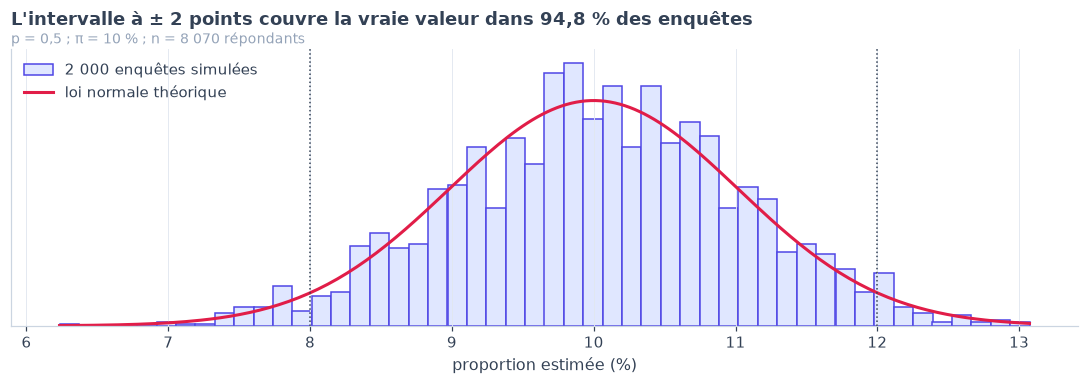

In [4]:
pi_, p_, n_ = 0.1, 0.5, 8070
var = et.rr_variance(pi_, p_, n_)
print(f"n requis (randomisé) : {0.84 * (1.96 / 0.02) ** 2:.0f} ; direct : {0.09 * (1.96 / 0.02) ** 2:.0f}")
ests = []
for s in range(2000):
    r = np.random.default_rng(10_000 + s)
    truth = (r.random(n_) < pi_).astype(int)
    ests.append(et.rr_estimate(et.randomized_response(truth, p_, r), p_))
ests = np.array(ests)
cover = np.mean(np.abs(ests - pi_) <= 1.96 * np.sqrt(var))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(ests * 100, bins=50, color=LIGHT[INDIGO], edgecolor=INDIGO, density=True, label="2 000 enquêtes simulées")
xx = np.linspace(ests.min(), ests.max(), 200)
ax.plot(xx * 100, np.exp(-(xx - pi_) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var) / 100, color=ROSE, label="loi normale théorique")
for sgn in (-1, 1):
    ax.axvline((pi_ + sgn * 1.96 * np.sqrt(var)) * 100, color=SLATE, ls=":", lw=1)
ax.set_xlabel("proportion estimée (%)"); ax.set_yticks([])
ax.set_title(f"L'intervalle à ± 2 points couvre la vraie valeur dans {cover * 100:.1f} % des enquêtes".replace(".", ","))
subtitle(ax, "p = 0,5 ; π = 10 % ; n = 8 070 répondants")
ax.legend()
plt.tight_layout(); plt.show()

La distribution des estimations suit la loi normale prévue et l'intervalle couvre la
vraie valeur dans environ 95 % des cas. Chaque répondant, lui, garde un déni plausible :
une réponse « oui » n'est jamais une preuve.

> **À retenir.** La réponse randomisée échange de la précision statistique (ici un
> facteur 9 sur la taille d'échantillon) contre une protection individuelle mesurable
> (un rapport de vraisemblance borné par 3). C'est le principe de la confidentialité
> différentielle : apprendre sur la population sans apprendre sur l'individu.

## Exercice 12.14 : la boucle de rétroaction des patrouilles

**Énoncé.** On reprend le modèle du cours 6 (`et.patrol_feedback`) : deux
quartiers, des patrouilles réparties selon les incidents **enregistrés**, et on
n'enregistre que ce que voit une patrouille.

1. Avec l'allocation **au prorata** et des taux réels égaux, montrer que la part
   enregistrée du quartier 1 est, en espérance, constante d'un jour à l'autre. Qu'en
   déduire sur sa valeur finale ?
2. Avec l'allocation **au point chaud**, que se passe-t-il ? La correction par
   pondération inverse suffit-elle à réparer ce cas ?
3. Les taux réels sont maintenant 1,0 et 1,5 (le quartier 2 a 50 % d'incidents en plus).
   Que donnent les trois stratégies (prorata, point chaud, prorata corrigé) sur 200
   simulations ?

**Rappels.** Cours 6, section 4 (sous-section *Feedback loops*) : quand les données de demain sont produites par
les décisions d'aujourd'hui, de petites différences initiales s'amplifient.

**Solution.**

*1.* Soit $x_t$ la part enregistrée du quartier 1. On lui envoie en moyenne une part
$x_t$ des patrouilles, qui y découvrent des incidents au même taux qu'ailleurs : les
nouveaux incidents enregistrés se répartissent donc en moyenne selon $x_t$, et la part
reste $x_t$ en espérance. C'est une **martingale** (le modèle de l'urne de Pólya) : elle
converge, mais vers une valeur **aléatoire**, fixée par le hasard des premiers jours,
et non vers la vérité (50 %). Les données ne corrigent jamais l'erreur initiale.

*2.* Au point chaud, le quartier en tête reçoit toutes les patrouilles ; l'autre n'est
plus jamais observé, sa part tend vers 0. La pondération inverse ne peut rien : on ne
corrige pas un échantillon **vide**. Il faut **explorer**, garder une part minimale
d'observations partout, comme un bandit manchot qui teste encore les autres bras.

*3.* Voir le mini-lab : seule la stratégie corrigée retrouve la vraie part (40 %) ; le
prorata amplifie la différence réelle, le point chaud l'ignore.

**Vérification** : 200 simulations par stratégie et par scénario.

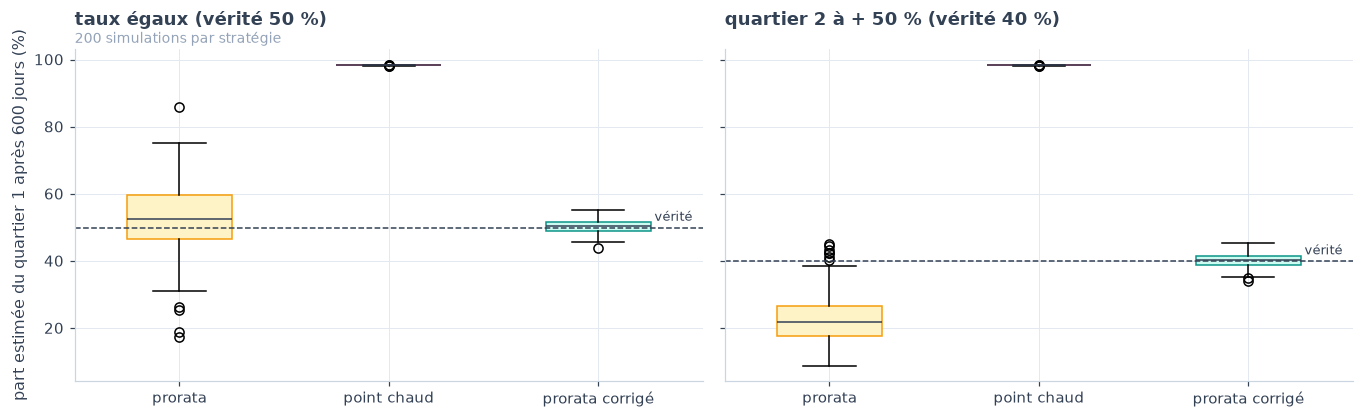

,prorata,point chaud,prorata corrigé
taux égaux (vérité 50 %),52 % (écart type 11),98 % (écart type 0),50 % (écart type 2)
quartier 2 à + 50 % (vérité 40 %),23 % (écart type 7),98 % (écart type 0),40 % (écart type 2)


In [5]:
scen = {"taux égaux (vérité 50 %)": (1.0, 1.0), "quartier 2 à + 50 % (vérité 40 %)": (1.0, 1.5)}
strat = {"prorata": ("proportional", False), "point chaud": ("hotspot", False), "prorata corrigé": ("proportional", True)}
final = {}
for sname, rates in scen.items():
    for k, (pol, cor) in strat.items():
        final[(sname, k)] = np.array([et.patrol_feedback(true_rates=rates, policy=pol, correct=cor, days=600, seed=s)[-1, 0]
                                      for s in range(200)])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True)
for ax, (sname, rates) in zip(axes, scen.items()):
    truth = rates[0] / sum(rates)
    data = [final[(sname, k)] * 100 for k in strat]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops=dict(color=SLATE))
    for patch, c in zip(bp["boxes"], [AMBER, ROSE, TEAL]):
        patch.set_facecolor(LIGHT[c]); patch.set_edgecolor(c)
    ax.set_xticks([1, 2, 3], list(strat))
    ax.axhline(truth * 100, color=SLATE, ls="--", lw=1)
    ax.text(3.45, truth * 100 + 2, "vérité", fontsize=8.5, color=SLATE, ha="right")
    ax.set_title(sname)
axes[0].set_ylabel("part estimée du quartier 1 après 600 jours (%)")
subtitle(axes[0], "200 simulations par stratégie")
plt.tight_layout(); plt.show()
pd.DataFrame({k: {s: f"{final[(s, k)].mean() * 100:.0f} % (écart type {final[(s, k)].std() * 100:.0f})" for s in scen}
              for k in strat})

- Au prorata, avec des taux égaux, la moyenne sur les simulations est juste, mais
  **chaque** simulation se fige loin de la vérité (écart type de 11 points) : une ville
  réelle n'a qu'une trajectoire. Avec des taux inégaux, la boucle **exagère** l'écart :
  le quartier 1 n'est plus crédité que de 23 % des incidents au lieu de 40 %, car le
  quartier le plus touché attire plus de patrouilles, qui y trouvent plus d'incidents.
- Au point chaud, l'issue dépend du départ (11 incidents contre 10), pas de la réalité :
  même quand le quartier 1 est le **moins** touché, il reçoit toutes les patrouilles et
  presque 100 % des incidents enregistrés.
- La correction par pondération inverse retrouve 50 % puis 40 %, avec une faible
  dispersion.

> **À retenir.** Un système qui apprend de données produites par ses propres décisions
> peut se figer sur une erreur (martingale) ou s'emballer (point chaud). Il faut
> corriger le biais d'échantillonnage et garder de l'exploration ; sans observations,
> aucune correction n'est possible.

## Exercice 12.15 : durée de conservation et risque de fuite

**Énoncé.** Une application de mobilité compte 2 millions d'utilisateurs ; chacun
produit 200 points de localisation par jour (16 octets chacun). On estime à 10 % par an
la probabilité d'une fuite majeure, qui emporterait tout ce qui est conservé.

1. Quel volume de données brutes est conservé pour une durée de conservation $R$ de 7
   jours, 1 an, 5 ans ? Combien de jours d'historique de localisation d'une personne
   une fuite révèle-t-elle ?
2. Quelle est la probabilité d'au moins une fuite sur 10 ans ? Dépend-elle de $R$ ?
3. On remplace les points bruts de plus de 7 jours par des **agrégats** : nombre de
   personnes par zone (1 000 zones) et par heure. Quel volume pour un an d'agrégats ?
   Que révèle une fuite de ces agrégats ?
4. Le service conserve les données brutes 20 ans. Avec 1 % par an de risque qu'un
   gouvernement exige un jour ces données, quelle probabilité sur la période ?

**Rappels.** Cours 7, sections 5 et 7 (sous-sections *Data as assets and power*, *Legislation and self-regulation*) : les
données sont un actif toxique ; l'exposition croît avec la durée de conservation ;
minimiser et purger.

**Solution.**

*1.* Débit brut : $2 \cdot 10^6 \times 200 \times 16 = 6{,}4$ Go par jour. Stock : **45 Go**
pour 7 jours, **2,3 To** pour un an, **11,7 To** pour 5 ans. Une fuite révèle $R$ jours de
trajets de **chaque** utilisateur : une semaine de déplacements, ou cinq ans
(domicile, travail, médecin, lieux de culte...).

*2.* Nombre de fuites en 10 ans : Poisson de moyenne 1, donc $P(\ge 1) = 1 - e^{-1}
\approx$ **63 %**, indépendamment de $R$. La durée de conservation ne change pas la
probabilité d'une fuite, elle change sa **gravité**.

*3.* $1\,000 \times 24 \times 365 \times 8$ octets $\approx$ **70 Mo** par an, soit plus de
30 000 fois moins que les données brutes d'un an. Une fuite révèle des affluences par
zone, pas des trajets individuels (à condition que les zones et les heures peu
fréquentées soient elles aussi protégées, sinon un comptage de 1 identifie).

*4.* $1 - 0{,}99^{20} \approx$ **18 %**.

**Vérification** : volumes, puis simulation des fuites sur 10 ans selon $R$.

R =    7 j : stock brut   0.04 To
R =  365 j : stock brut   2.34 To
R = 1825 j : stock brut  11.68 To
agrégats d'un an : 70 Mo ; P(fuite sur 10 ans) = 63% ; P(gouvernement hostile sur 20 ans) = 18%


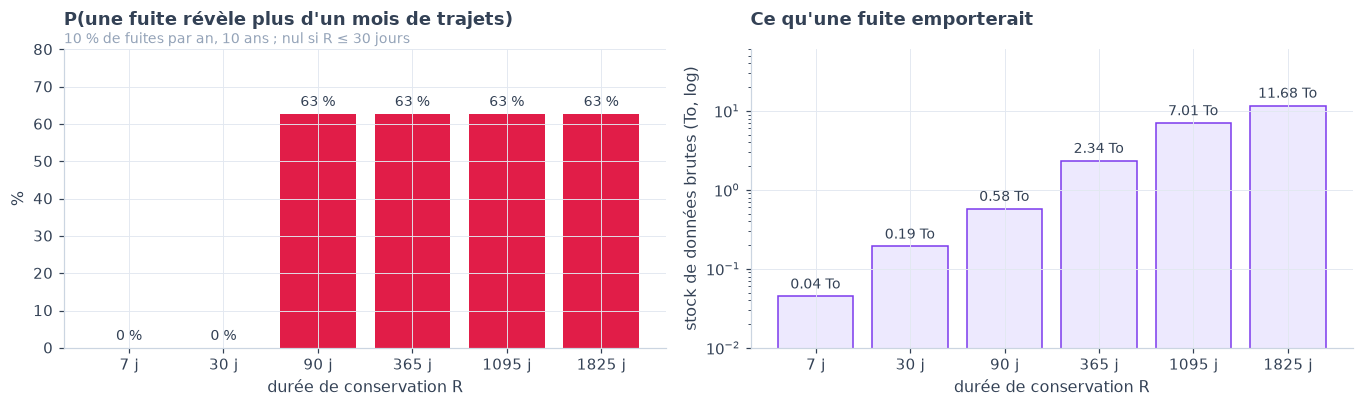

In [6]:
daily = 2e6 * 200 * 16
for R in (7, 365, 5 * 365):
    print(f"R = {R:>4} j : stock brut {daily * R / 1e12:6.2f} To")
print(f"agrégats d'un an : {1000 * 24 * 365 * 8 / 1e6:.0f} Mo ; P(fuite sur 10 ans) = {1 - np.exp(-1):.0%} ; "
      f"P(gouvernement hostile sur 20 ans) = {1 - 0.99 ** 20:.0%}")

Rs = np.array([7, 30, 90, 365, 3 * 365, 5 * 365])
r_ = np.random.default_rng(1)
k = r_.poisson(0.1 * 10, size=20_000)                    # fuites sur 10 ans
days_exposed = {R: np.where(k > 0, R, 0) for R in Rs}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax = axes[0]
ax.bar([f"{R} j" for R in Rs], [np.mean(days_exposed[R] > 30) * 100 for R in Rs],
       color=[GREEN, GREEN, ROSE, ROSE, ROSE, ROSE])
annotate_bars(ax, "{:.0f} %")
ax.set_ylim(0, 80)
ax.set_xlabel("durée de conservation R"); ax.set_ylabel("%")
ax.set_title("P(une fuite révèle plus d'un mois de trajets)")
subtitle(ax, "10 % de fuites par an, 10 ans ; nul si R ≤ 30 jours")
ax = axes[1]
volume = [daily * R / 1e12 for R in Rs]
ax.bar([f"{R} j" for R in Rs], volume, color=LIGHT[VIOLET], edgecolor=VIOLET)
annotate_bars(ax, "{:.2f} To")
ax.set_yscale("log"); ax.set_ylim(0.01, 60)
ax.set_xlabel("durée de conservation R"); ax.set_ylabel("stock de données brutes (To, log)")
ax.set_title("Ce qu'une fuite emporterait")
plt.tight_layout(); plt.show()

La probabilité d'au moins une fuite (63 %) ne dépend pas de la durée de conservation ;
ce qui en dépend, c'est l'ampleur des dégâts. En gardant 30 jours au plus de données
brutes et des agrégats au-delà, l'entreprise rend impossible la pire fuite (des années
de trajets de millions de personnes), tout en gardant les statistiques utiles.

> **À retenir.** On ne contrôle pas bien la probabilité d'une fuite ; on contrôle ce
> qu'elle emporterait. Purger les données brutes et ne conserver que des agrégats
> réduit l'exposition de plusieurs ordres de grandeur pour un coût faible.